# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
# 1. Ensure you are in the repository root directory
%cd /Users/siddhantmathapati/Downloads/data_Visualization_Siddhant_41724324

# 2. Tell Git to use merge (resolves the "divergent branches" error permanently)
!git config pull.rebase false

# 3. Pull from upstream (--no-edit prevents Jupyter from freezing on the commit message)
!git pull --no-rebase --no-edit upstream main

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
/Users/siddhantmathapati/Downloads/data_Visualization_Siddhant_41724324
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 33 (delta 18), reused 24 (delta 9), pack-reused 0 (from 0)
Unpacking objects: 100% (33/33), 4.68 MiB | 2.85 MiB/s, done.
From https://github.com/dina-deifallah/data-viz-class-material-w2026
 * branch            main       -> FETCH_HEAD
   defcb8e..b23ff9e  main       -> upstream/main
error: The following untracked working tree files would be overwritten by merge:
	week03/lecture03_exercise.ipynb
	week03/lecture03_notes.ipynb
Please move or remove them before you merge.
Aborting
Merge with strategy ort failed.


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 345 entries, 0 to 344
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country         345 non-null    object 
 1   Region          345 non-null    object 
 2   Year            345 non-null    int64  
 3   CO2_Mt          345 non-null    float64
 4   CO2_per_capita  345 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 13.6+ KB


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

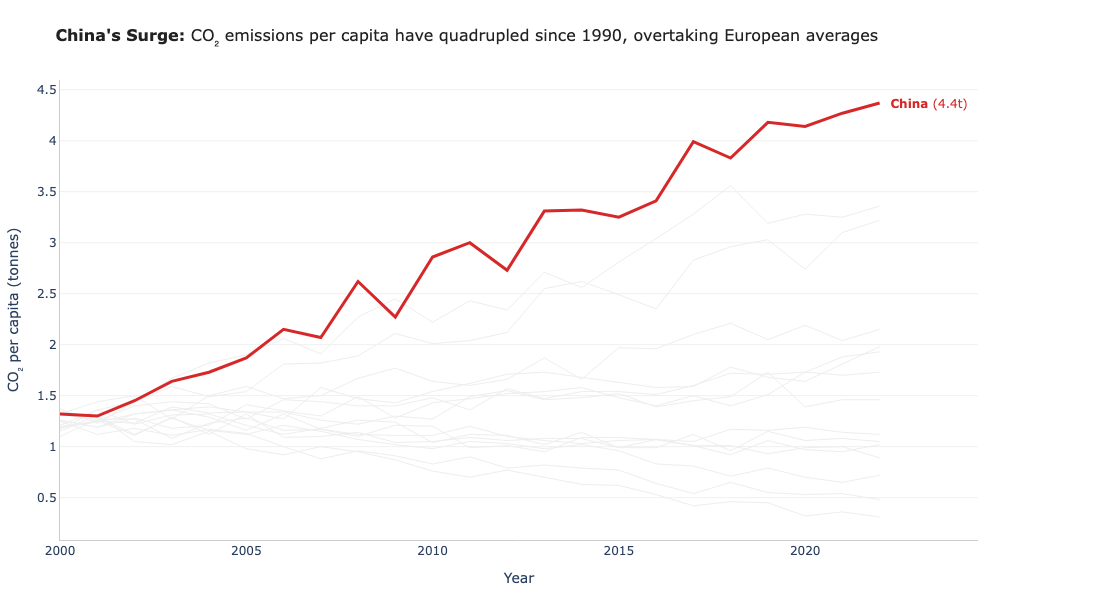

In [8]:

# ---------------------------------------------------------
# 1. Configuration & Column Mapping
# ---------------------------------------------------------
# Set your DataFrame name and verify column names:
country_col = 'Country'          
year_col    = 'Year'             
co2_col     = 'CO2_per_capita'   

highlight_country = 'China'     

fig = go.Figure()

# ---------------------------------------------------------
# 2. Add Background Lines (Grey #EEEEEE, Thinner, No Legend)
# ---------------------------------------------------------
for country, group in df.groupby(country_col):
    if country != highlight_country:
        clean_group = group.dropna(subset=[co2_col]).sort_values(year_col)
        fig.add_trace(go.Scatter(
            x=clean_group[year_col],
            y=clean_group[co2_col],
            mode='lines',
            line=dict(color='#EEEEEE', width=1),
            hoverinfo='skip',     # Keeps the interactive plot fast and clean
            showlegend=False
        ))

# ---------------------------------------------------------
# 3. Add Highlighted Country Line (Thicker, Bold Color)
# ---------------------------------------------------------
target = df[df[country_col] == highlight_country].dropna(subset=[co2_col]).sort_values(year_col)

fig.add_trace(go.Scatter(
    x=target[year_col],
    y=target[co2_col],
    mode='lines',
    line=dict(color='#D62828', width=3),
    hovertemplate=f"<b>{highlight_country}</b><br>Year: %{{x}}<br>CO₂: %{{y:.2f}} tonnes<extra></extra>",
    showlegend=False
))

# ---------------------------------------------------------
# 4. Direct Label at the End of the Line (No Legend)
# ---------------------------------------------------------
last_row  = target.iloc[-1]
last_year = last_row[year_col]
last_co2  = last_row[co2_col]

fig.add_annotation(
    x=last_year,
    y=last_co2,
    text=f"  <b>{highlight_country}</b> ({last_co2:.1f}t)",
    showarrow=False,
    xanchor="left",
    yanchor="middle",
    font=dict(color="#D62828", size=12)
)

# ---------------------------------------------------------
# 5. Insight Title & Layout Styling
# ---------------------------------------------------------
fig.update_layout(
    title=dict(
        text="<b>China's Surge:</b> CO₂ emissions per capita have quadrupled since 1990, overtaking European averages",
        font=dict(size=16, color="#222222"),
        x=0.05,
        y=0.95
    ),
    plot_bgcolor="white",
    showlegend=False,
    xaxis=dict(
        title="Year",
        showgrid=False,
        linecolor="#CCCCCC",
        # Give padding on the right so the text label isn't clipped
        range=[df[year_col].min(), last_year + (last_year - df[year_col].min()) * 0.12]
    ),
    yaxis=dict(
        title="CO₂ per capita (tonnes)",
        showgrid=True,
        gridcolor="#F0F0F0",
        linecolor="#CCCCCC"
    ),
    margin=dict(l=60, r=130, t=80, b=60),
    width=950,
    height=600
)

fig.show()

---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

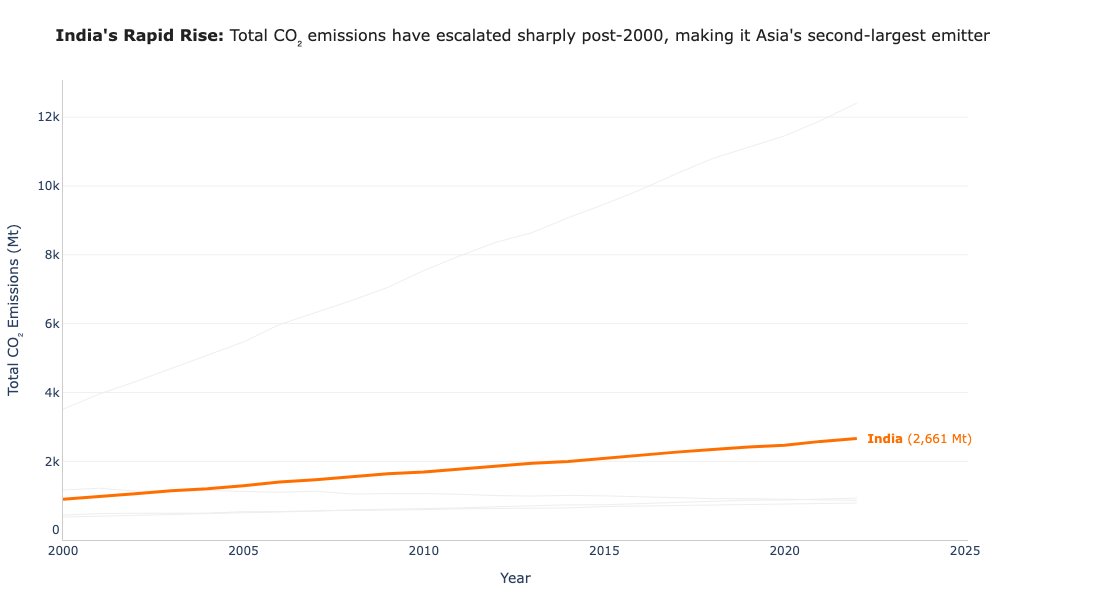

In [9]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
# 1. Filter for Asian countries using the 'Region' column
asia_df = df[df['Region'].str.contains('Asia', case=False, na=False)].copy()
highlight_country = 'India'
fig2 = go.Figure()
# 2. Background lines (All other Asian countries in #EEEEEE)
for country, group in asia_df.groupby('Country'):
    if country != highlight_country:
        clean = group.dropna(subset=['CO2_Mt']).sort_values('Year')
        fig2.add_trace(go.Scatter(
            x=clean['Year'],
            y=clean['CO2_Mt'],
            mode='lines',
            line=dict(color='#EEEEEE', width=1),
            hoverinfo='skip',
            showlegend=False
        ))
# 3. Highlighted country
target_asia = asia_df[asia_df['Country'] == highlight_country].dropna(subset=['CO2_Mt']).sort_values('Year')
fig2.add_trace(go.Scatter(
    x=target_asia['Year'],
    y=target_asia['CO2_Mt'],
    mode='lines',
    line=dict(color='#FF6F00', width=3),  # Bold amber/orange
    hovertemplate=f"<b>{highlight_country}</b><br>Year: %{{x}}<br>CO₂: %{{y:,.1f}} Mt<extra></extra>",
    showlegend=False
))
# 4. Direct label at the end of the line
last_pt_asia = target_asia.iloc[-1]
fig2.add_annotation(
    x=last_pt_asia['Year'],
    y=last_pt_asia['CO2_Mt'],
    text=f"  <b>{highlight_country}</b> ({last_pt_asia['CO2_Mt']:,.0f} Mt)",
    showarrow=False,
    xanchor="left",
    yanchor="middle",
    font=dict(color="#FF6F00", size=12)
)
# 5. Insight title and layout
fig2.update_layout(
    title=dict(
        text="<b>India's Rapid Rise:</b> Total CO₂ emissions have escalated sharply post-2000, making it Asia's second-largest emitter",
        font=dict(size=16, color="#222222"),
        x=0.05,
        y=0.95
    ),
    plot_bgcolor="white",
    showlegend=False,
    xaxis=dict(
        title="Year",
        showgrid=False,
        linecolor="#CCCCCC",
        range=[asia_df['Year'].min(), last_pt_asia['Year'] + (last_pt_asia['Year'] - asia_df['Year'].min()) * 0.14]
    ),
    yaxis=dict(
        title="Total CO₂ Emissions (Mt)",
        showgrid=True,
        gridcolor="#F0F0F0",
        linecolor="#CCCCCC"
    ),
    margin=dict(l=60, r=140, t=80, b=60),
    width=950,
    height=600
)
fig2.show()

In [ ]:
# 1. Ensure you are in your main repository folder
%cd /Users/siddhantmathapati/Downloads/data_Visualization_Siddhant_41724324

# 2. Stage all changed files
!git add .

# 3. Commit with a message
!git commit -m "Complete Week 03 exercises"

# 4. Push your commits to GitHub
!git push origin main